<a href="https://colab.research.google.com/github/Zaky-hub25/2418006_Data_Visualization_Transaksi_Crypto/blob/main/Data_Visualization_2418006.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

2. Memuat Dataset

In [ ]:
uploaded = files.upload()
nama_file = next(iter(uploaded))

df = pd.read_excel(
    nama_file,
    sheet_name="Transaksi_100"
)

print("Ukuran dataset:", df.shape)
display(df.head())

Saving Data_Visualization_Transaksi_Crypto.xlsx to Data_Visualization_Transaksi_Crypto.xlsx
Ukuran dataset: (100, 11)


,ID_Transaksi,Tanggal,Crypto,Jenis_Transaksi,Harga_per_Coin_Rp,Jumlah_Crypto,Total_Nilai_Rp,Fee_Rp,Profit_Loss_Rp,Exchange,Status
0,TX001,2026-01-01,BTC,Sell,1006379964,0.000254,255750,158,579,OKX,Success
1,TX002,2026-01-03,BNB,Buy,11330300,0.303834,3442533,6545,0,Binance,Success
2,TX003,2026-01-05,ETH,Buy,57854685,0.048852,2826306,1863,0,Indodax,Success
3,TX004,2026-01-07,BTC,Buy,1109914195,0.001588,1762255,925,0,Bybit,Pending
4,TX005,2026-01-09,SOL,Buy,2665974,7.995296,21315254,37250,0,Bybit,Pending


3. Memeriksa Dataset

In [ ]:
print("Informasi dataset:")
df.info()

print("\nJumlah data kosong:")
print(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID_Transaksi       100 non-null    object 
 1   Tanggal            100 non-null    object 
 2   Crypto             100 non-null    object 
 3   Jenis_Transaksi    100 non-null    object 
 4   Harga_per_Coin_Rp  100 non-null    int64  
 5   Jumlah_Crypto      100 non-null    float64
 6   Total_Nilai_Rp     100 non-null    int64  
 7   Fee_Rp             100 non-null    int64  
 8   Profit_Loss_Rp     100 non-null    int64  
 9   Exchange           100 non-null    object 
 10  Status             100 non-null    object 
dtypes: float64(1), int64(4), object(6)
memory usage: 8.7+ KB

Jumlah data kosong:
ID_Transaksi         0
Tanggal              0
Crypto               0
Jenis_Transaksi      0
Harga_per_Coin_Rp    0
Jumlah_Crypto        0
Total_Nilai_Rp       0
Fee_Rp   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID_Transaksi,100,100,TX001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tanggal,100,100,2026-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crypto,100,5,BTC,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jenis_Transaksi,100,2,Buy,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Harga_per_Coin_Rp,100.0,NaN,NaN,NaN,325475749.12,477469856.000311,32908.0,2605724.0,52551359.5,1005530646.5,1127369186.0
Jumlah_Crypto,100.0,NaN,NaN,NaN,16.101436,67.257626,0.000254,0.002599,0.06403,1.693411,426.677747
Total_Nilai_Rp,100.0,NaN,NaN,NaN,4775567.23,5157883.663621,255750.0,1694454.0,2832599.0,4556153.0,21315254.0
Fee_Rp,100.0,NaN,NaN,NaN,6207.6,7445.672586,158.0,1812.25,3821.0,6616.0,37250.0
Profit_Loss_Rp,100.0,NaN,NaN,NaN,28147.93,200006.31247,-752722.0,0.0,0.0,30760.5,1097034.0
Exchange,100,4,Bybit,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN


4. Membersihkan Data

In [ ]:
data = df.copy()

data["Tanggal"] = pd.to_datetime(
    data["Tanggal"], errors="coerce"
)

kolom_angka = [
    "Harga_per_Coin_Rp",
    "Jumlah_Crypto",
    "Total_Nilai_Rp",
    "Fee_Rp",
    "Profit_Loss_Rp"
]

for kolom in kolom_angka:
    data[kolom] = pd.to_numeric(
        data[kolom], errors="coerce"
    )

data = data.drop_duplicates()

print("Ukuran data setelah dibersihkan:", data.shape)
print("\nNilai kosong setelah pembersihan:")
print(data.isnull().sum())

Ukuran data setelah dibersihkan: (100, 11)

Nilai kosong setelah pembersihan:
ID_Transaksi         0
Tanggal              0
Crypto               0
Jenis_Transaksi      0
Harga_per_Coin_Rp    0
Jumlah_Crypto        0
Total_Nilai_Rp       0
Fee_Rp               0
Profit_Loss_Rp       0
Exchange             0
Status               0
dtype: int64


5. Histogram Data Numerik

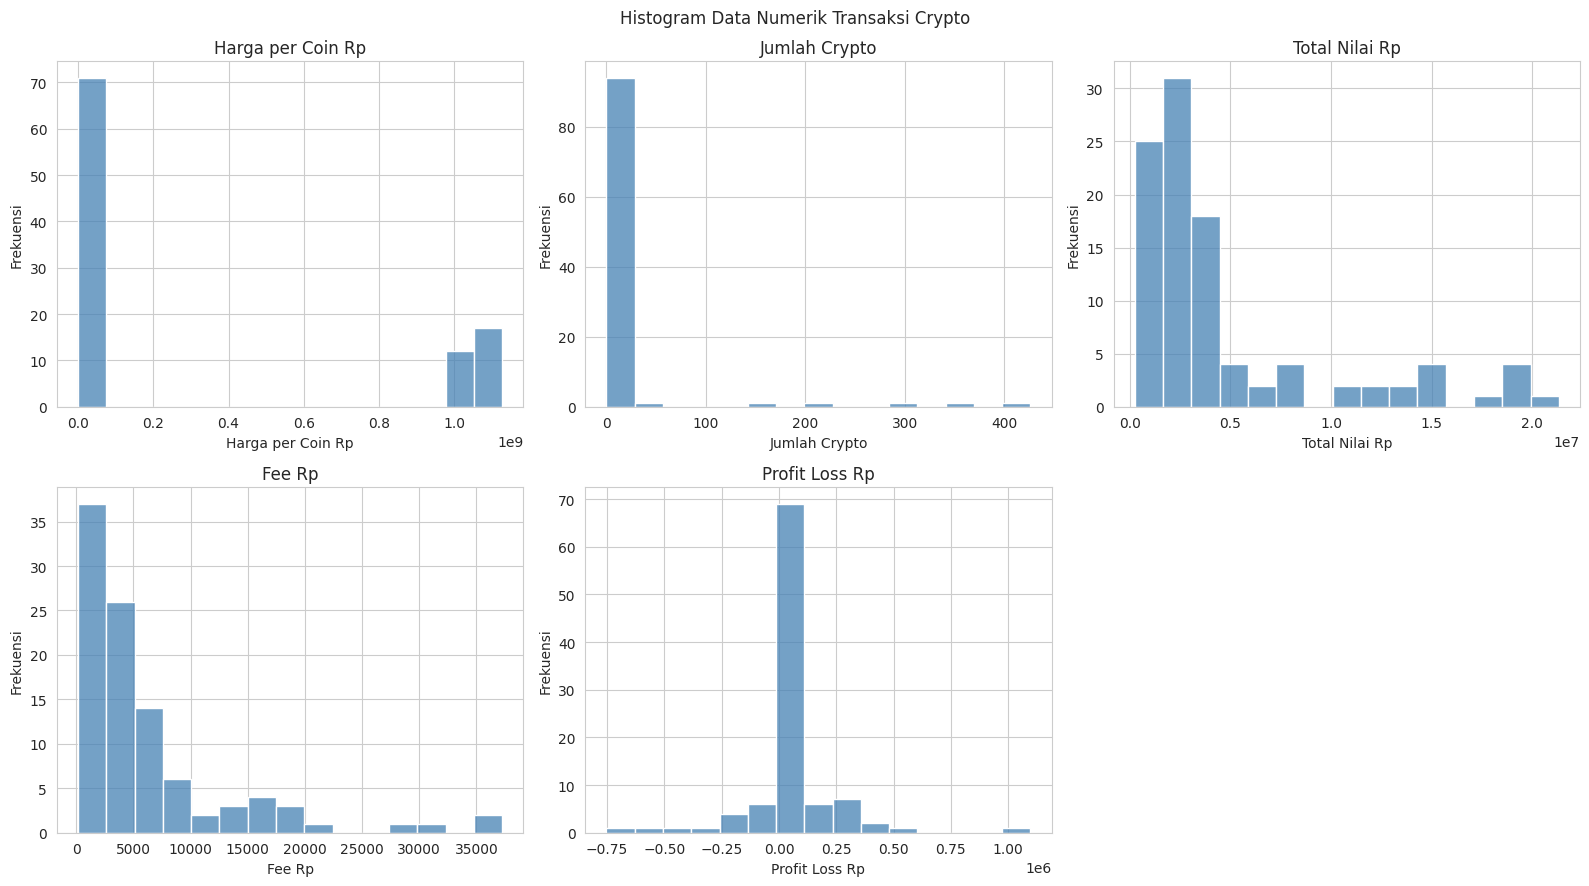

In [ ]:
kolom = [
    "Harga_per_Coin_Rp",
    "Jumlah_Crypto",
    "Total_Nilai_Rp",
    "Fee_Rp",
    "Profit_Loss_Rp"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, kolom_data in enumerate(kolom):
    sns.histplot(
        data=data,
        x=kolom_data,
        bins=15,
        kde=False,
        ax=axes[i],
        color="steelblue"
    )
    axes[i].set_title(kolom_data.replace("_", " "))
    axes[i].set_xlabel(kolom_data.replace("_", " "))
    axes[i].set_ylabel("Frekuensi")

axes[-1].axis("off")
plt.suptitle("Histogram Data Numerik Transaksi Crypto")
plt.tight_layout()
plt.show()

6. Distribusi Harga Crypto

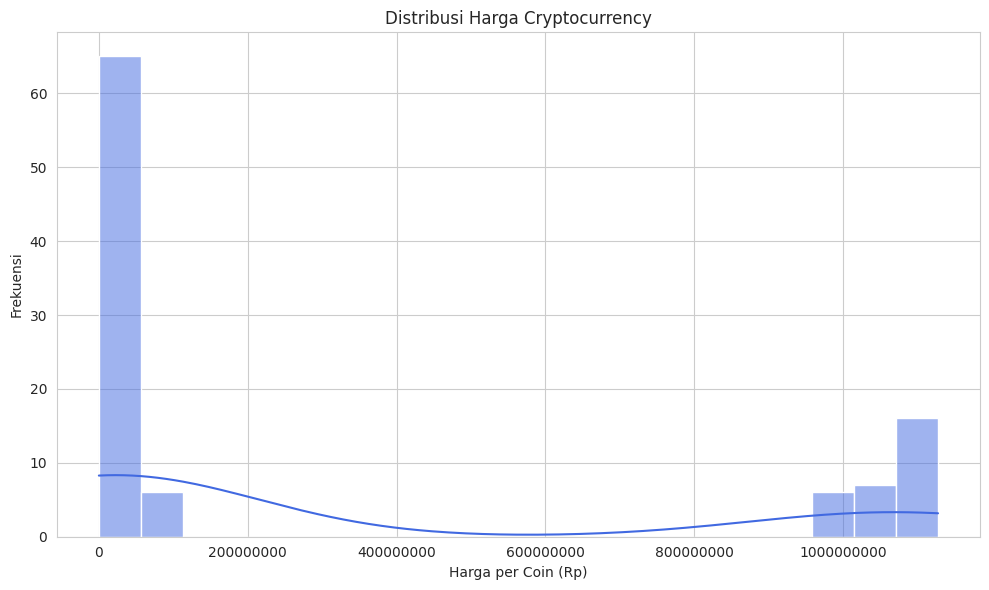

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x="Harga_per_Coin_Rp",
    bins=20,
    kde=True,
    color="royalblue"
)

plt.title("Distribusi Harga Cryptocurrency")
plt.xlabel("Harga per Coin (Rp)")
plt.ylabel("Frekuensi")
plt.ticklabel_format(
    axis="x", style="plain", useOffset=False
)
plt.tight_layout()
plt.show()

7. Visualisasi Kolom Kategori

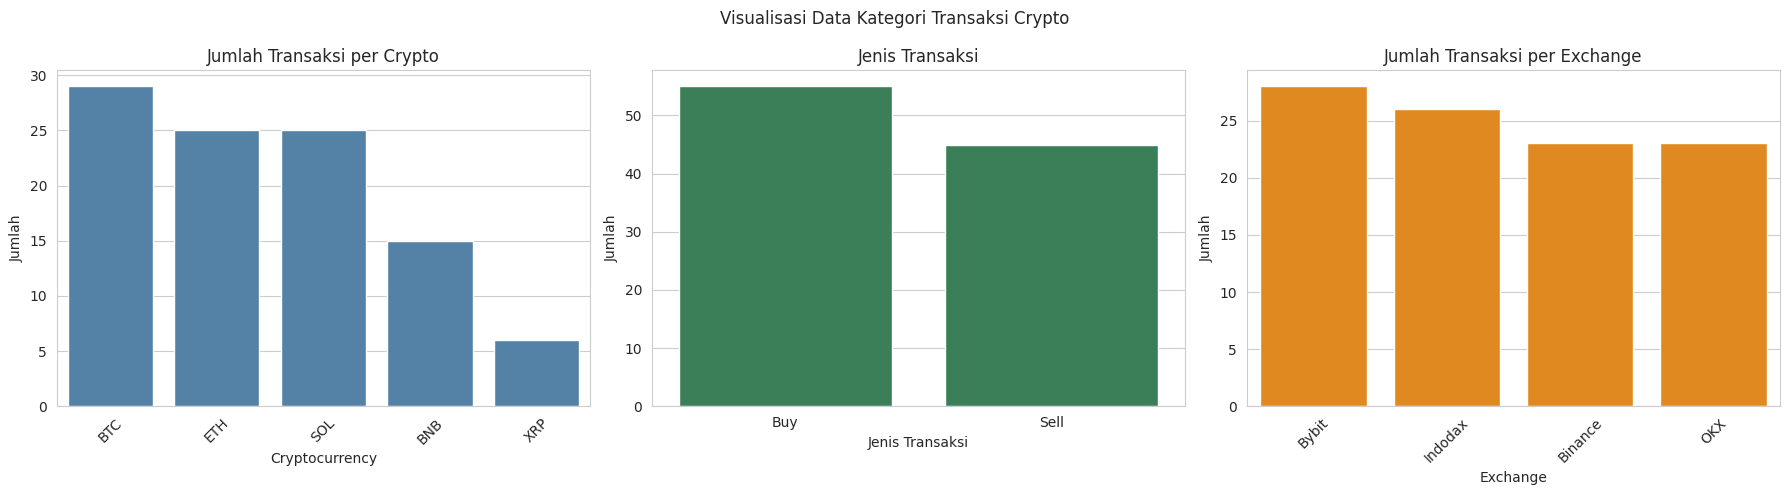

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(
    data=data,
    x="Crypto",
    order=data["Crypto"].value_counts().index,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Jumlah Transaksi per Crypto")
axes[0].set_xlabel("Cryptocurrency")
axes[0].set_ylabel("Jumlah")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(
    data=data,
    x="Jenis_Transaksi",
    order=data["Jenis_Transaksi"].value_counts().index,
    ax=axes[1],
    color="seagreen"
)
axes[1].set_title("Jenis Transaksi")
axes[1].set_xlabel("Jenis Transaksi")
axes[1].set_ylabel("Jumlah")

sns.countplot(
    data=data,
    x="Exchange",
    order=data["Exchange"].value_counts().index,
    ax=axes[2],
    color="darkorange"
)
axes[2].set_title("Jumlah Transaksi per Exchange")
axes[2].set_xlabel("Exchange")
axes[2].set_ylabel("Jumlah")
axes[2].tick_params(axis="x", rotation=45)

plt.suptitle("Visualisasi Data Kategori Transaksi Crypto")
plt.tight_layout()
plt.show()

8. Analisis Korelasi

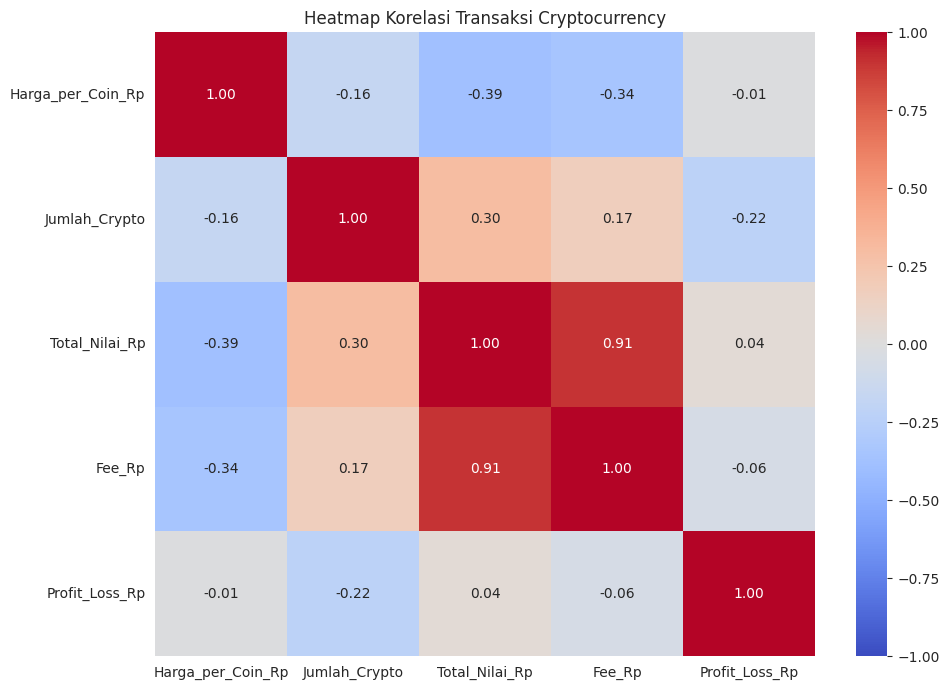

In [ ]:
kolom_korelasi = [
    "Harga_per_Coin_Rp",
    "Jumlah_Crypto",
    "Total_Nilai_Rp",
    "Fee_Rp",
    "Profit_Loss_Rp"
]

korelasi = data[kolom_korelasi].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Heatmap Korelasi Transaksi Cryptocurrency")
plt.tight_layout()
plt.show()

9. Total Nilai Transaksi per Crypto

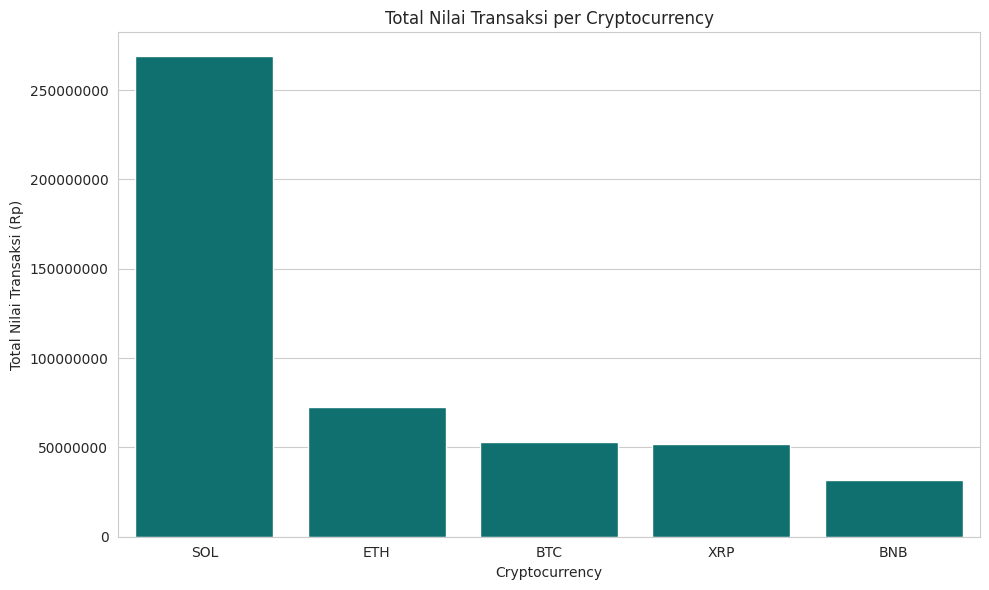

In [ ]:
total_crypto = (
    data.groupby("Crypto")["Total_Nilai_Rp"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=total_crypto.index,
    y=total_crypto.values,
    color="teal"
)

plt.title("Total Nilai Transaksi per Cryptocurrency")
plt.xlabel("Cryptocurrency")
plt.ylabel("Total Nilai Transaksi (Rp)")
plt.ticklabel_format(
    axis="y", style="plain", useOffset=False
)
plt.tight_layout()
plt.show()

10. Menyimpan Data yang Sudah Dibersihkan

In [ ]:
nama_output = "Data_Transaksi_Crypto_Bersih.xlsx"

data.to_excel(nama_output, index=False)

print("Data berhasil disimpan:", nama_output)

files.download(nama_output)

Data berhasil disimpan: Data_Transaksi_Crypto_Bersih.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>